
# Control de inventario (Prcoesos de Decision de Markov)

Usaremos un MDP para definir nuestro poroblema de control de inventario y averiguar cuál es el mejor momento para resurtir.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Ambiente

In [2]:
p_sale = 0.7 #Probabilidad de venta en un paso de tiempo
n_steps = 100 #Número de pasos considerados en cada episodio

## Acciones y Políticas
### Reto 1
Completa el código necesario para crear las 3 políticas
validas propuestas.

In [3]:


NONE = 0
RESTOCK = 1

def resurtir_siempre(current_state):
    if current_state == 2:
        return NONE
    else:
        return RESTOCK

    
def resurtir_random(current_state):
    if current_state ==2:
        return NONE
    if np.random.randint(2) == 0:
        return NONE
    else:
        return RESTOCK
    
def resurtir_sin_stock(current_state):
    if current_state == 0:
        return RESTOCK
    else:
        return NONE

## Matriz de transición

### Reto 2
Crea las matrices de transición.

In [4]:

transition_matrix = [
    # No action
    [
        [1, 0, 0],
        [p_sale, 1 - p_sale, 0],
        [0, p_sale, 1-p_sale],
    ],
    
    # Restock
    [
        [p_sale, 1- p_sale, 0],
        [0, p_sale, 1-p_sale],
    ],
]

## Matriz de recompensas

### Reto 3
Crea las matrices de recompensas

In [5]:

reward_matrix = [
    # No action
    [
        [0, 0, 0],
        [1, 0, 0],
        [0, 1, 0],
    ],
    # Restock
    [
        [1, 0, 0],
        [0, 1, 0],
    ],
]

## Ambiente

### Reto 4
 Usa las propabilidades de transición para seleccionar el
 estado sigueinte. Tip: puedes usar np.random.choice() 

In [6]:
def environment(current_state, action):
    # Obtener probabilidades de transición a s'
    prob_next_s = transition_matrix[action][current_state]
    
    # Usar la probabilidad de transición para ir a un nuevo s'
    next_state = np.random.choice(a=[0,1,2], p=prob_next_s)
    
    # Recompensa obtenida por ir al estado s'
    reward = reward_matrix[action][current_state][next_state]
    return (next_state, reward)

In [7]:
#Probando el ambiente
current_state = 1 #Un producto en stock
action = RESTOCK #Tomamos la acción de resurtir

for i in range(5):
    next_state, reward = environment(current_state, action)
    print(f"sim={i}: s={current_state}, a={action}, s'={next_state}, r={reward}")

sim=0: s=1, a=1, s'=2, r=0
sim=1: s=1, a=1, s'=1, r=1
sim=2: s=1, a=1, s'=1, r=1
sim=3: s=1, a=1, s'=1, r=1
sim=4: s=1, a=1, s'=1, r=1


## Probando las diferentes estrategias de control de inventario

In [8]:
strategies = [("resurtir_siempre", resurtir_siempre),
              ("resurtir_sin_stock", resurtir_sin_stock),
              ("resurtir_random", resurtir_random)]

history = []

for (policy_name, policy) in strategies:
    print('\n' + policy_name)
    
    reward_history = []
    current_state = 2 # Estado inicial
    total_reward = 0
    
    for i in range(n_steps):
        reward_history.append(total_reward)
        #Obtener una acción acorde a la estrategia
        action = policy(current_state)
        #Obtener r' y s'
        next_state, reward = environment(current_state, action)
        print("s: {}, s': {}, a: {}, r: {}."
              .format(current_state, next_state, action, reward))
        total_reward += reward
        current_state = next_state
    print(f"La recompensa total fue {total_reward}.")
    history.append(reward_history)


resurtir_siempre
s: 2, s': 2, a: 0, r: 0.
s: 2, s': 2, a: 0, r: 0.
s: 2, s': 1, a: 0, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 2, a: 1, r: 0.
s: 2, s': 1, a: 0, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 2, a: 1, r: 0.
s: 2, s': 1, a: 0, r: 1.
s: 1, s': 2, a: 1, r: 0.
s: 2, s': 1, a: 0, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 2, a: 1, r: 0.
s: 2, s': 2, a: 0, r: 0.
s: 2, s': 2, a: 0, r: 0.
s: 2, s': 1, a: 0, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s': 2, a: 1, r: 0.
s: 2, s': 1, a: 0, r: 1.
s: 1, s': 1, a: 1, r: 1.
s: 1, s

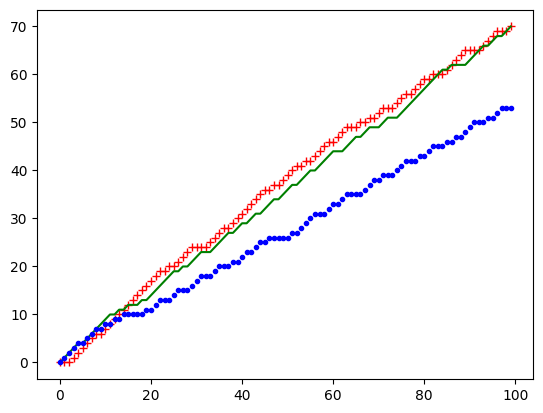

In [9]:
plt.plot(history[0], '+r')
plt.plot(history[1], '-g')
plt.plot(history[2], '.b')
plt.show()